In [7]:
from matplotlib import pyplot as plt
import numpy as np 
import os
import pandas as pd 
from pathlib import Path

In [63]:
from scaling.utils import (
    get_pareto_frontier, get_final_points_from_curve_set,
    functional_form_L0, fit_parametric_form
)

In [90]:
import sys

sys.path.append(str(Path(os.getcwd()).parent))

from parametric_forms import PARAMETRIC_FORMS

In [149]:
PLOT_PATH = Path(os.getcwd()).absolute().parent / "plots"
PLOT_PATH.mkdir(exist_ok=True, parents=True)

In [6]:
try:
    import gdown
except ImportError:
    !uv pip install gdown pyarrow
    import gdown

In [79]:
file_id = "1vr5Jq1TpTpnkb5CX5mcu2wWQQzbf-bmd"
output = "warmstarting_data.parquet"

# Download
if not os.path.exists(output):
    gdown.download(f"https://drive.google.com/uc?id={file_id}", output, quiet=False)

# Check it downloaded
if os.path.exists(output) and os.path.getsize(output) > 0:
    print(f"Downloaded: {output} ({os.path.getsize(output):,} bytes)")
    df = pd.read_parquet(output)
    print(df.shape)
    display(df.head())
else:
    raise FileNotFoundError("Download failed — check sharing permissions.")

Downloaded: warmstarting_data.parquet (32,406,828 bytes)
(2505049, 34)


tag,tokens,flops,Train Loss,Validation Loss,tkpm,base_N,target_N,shrink,adam_beta_1,adam_beta_2,...,mup,n_layer,n_embd,n_head,warmstart_type,method,shrinking,g_width,g_N,post_hoc_df
0,0,0.000000e+00,10.957504,10.984583,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
1,65536,1.268941e+13,11.012417,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
2,131072,2.537883e+13,10.583125,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
3,196608,3.806824e+13,9.702733,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
4,262144,5.075766e+13,8.710074,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...


In [76]:
df.target_N.unique(), df.tkpm.unique(), df.method.unique(), df.shrink.unique()

(array([  32270848,   77124608,  134561280,  287183360,  610488320,
        1217722368]),
 array([10., 20., 30.,  5.,  1.]),
 <ArrowStringArray>
 ['paws', 'mup', 'net2net']
 Length: 3, dtype: str,
 array([0.2, 0.4, 0.6, 0.8, 1. , 0. ]))

In [81]:
df = df.loc[
    # (df.method == "paws") &
    # (df.shrink.isin([0.4, 1.0]))
    (df.method != "net2net") &
    (df.shrink == 0.4)
]

In [82]:
_df = get_final_points_from_curve_set(
    df, ["base_N", "target_N", "tkpm", "method"], x_col="flops", y_col="Validation Loss", get_pareto=True
).dropna()

In [141]:
best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _df["flops"].values, _df["Validation Loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)

<Figure size 640x480 with 0 Axes>

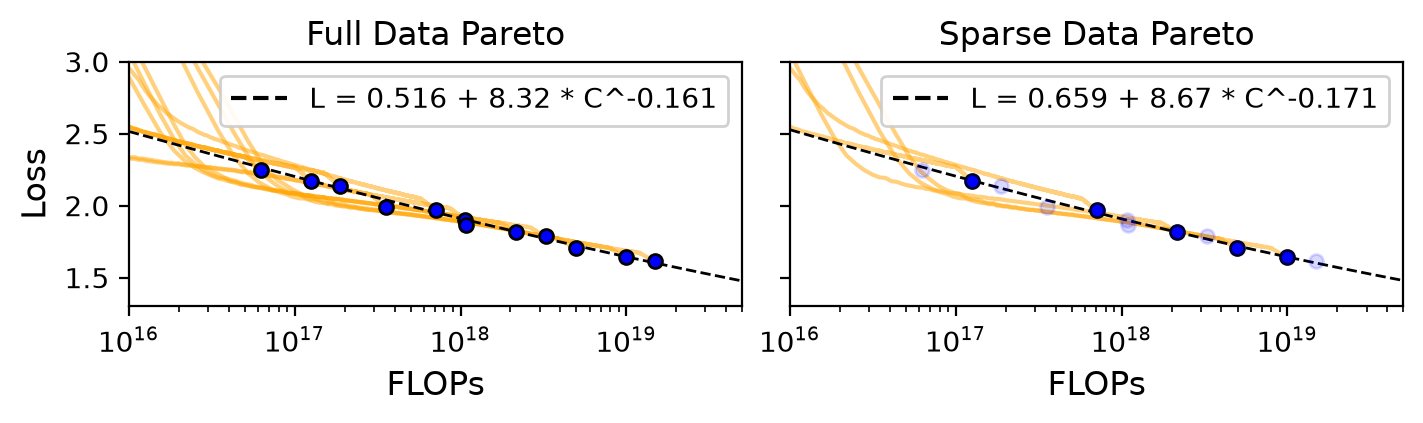

In [151]:
from matplotlib.lines import Line2D

plt.clf()

fig, axes = plt.subplots(1, 2, figsize=(7, 2), dpi=200, sharex=True, sharey=True, constrained_layout=True)

ax = axes[0]
for idx, row in _df.iterrows():
    _lc_df = df.loc[
        (df.base_N == row.base_N) &
        (df.target_N == row.target_N) &
        (df.tkpm == row.tkpm),
        ["flops", "Validation Loss"]
    ].dropna()
    ax.plot(_lc_df["flops"], _lc_df["Validation Loss"], alpha=0.5, color="orange")
    ax.scatter(row["flops"], row["Validation Loss"], color="blue", s=25, zorder=10, marker="o", edgecolor="black")

_flops = np.logspace(16, 20, 100)
ax.plot(
    _flops, PARAMETRIC_FORMS["L0"].func(_flops, best_params), 
    color="black", linestyle="--", linewidth=1
)

ax.set_ylim(1.3, 3)
ax.set_xlim(1e16, 5e19)
ax.set_xscale("log")

# --- custom legend ---
L0, A, alpha = best_params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Full Data Pareto", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_xlabel("FLOPs", fontsize=12)

##############

# subset_idx = [0, 2, 5, 7, 9, 10]
subset_idx = [1, 4, 7, 9, 10]
# subset_idx = [1, 3, 5, 7, 9, 11]
_subset_df = _df.iloc[subset_idx]

### refit params
_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _subset_df["flops"].values, _subset_df["Validation Loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)

ax = axes[1]
for idx, row in _subset_df.iterrows():
    _lc_df = df.loc[
        (df.base_N == row.base_N) &
        (df.target_N == row.target_N) &
        (df.tkpm == row.tkpm),
        ["flops", "Validation Loss"]
    ].dropna()
    ax.plot(_lc_df["flops"], _lc_df["Validation Loss"], alpha=0.5, color="orange")
    ax.scatter(row["flops"], row["Validation Loss"], color="blue", s=25, zorder=10, marker="o", edgecolor="black")

ax.scatter(
    _df["flops"], _df["Validation Loss"], 
    color="blue", s=25, zorder=10, marker="o", edgecolor="blue", alpha=0.15
)

_flops = np.logspace(16, 20, 100)
ax.plot(
    _flops, PARAMETRIC_FORMS["L0"].func(_flops, _best_params), 
    color="black", linestyle="--", linewidth=1
)

ax.set_ylim(1.3, 3)
ax.set_xlim(1e16, 5e19)
ax.set_xscale("log")

# --- custom legend ---
L0, A, alpha = _best_params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Sparse Data Pareto", fontsize=12)
ax.set_xlabel("FLOPs", fontsize=12)

plt.savefig(PLOT_PATH / "figure1_warmstarting_data.pdf", dpi=200, bbox_inches="tight")

---